# Chapter 15: A Graph Is a Story

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will read a graph as a story about two quantities: see whether a line includes the spots between its tick marks, compute a slope from two points without scrambling the signs, find intercepts and ask whether they mean anything, and find where two lines cross.

**A note on the code.** The code cells are optional reading. Every result and every picture is shown right below the cell that makes it, so you can follow along without running anything. If you do want to experiment, change a number in a cell and run it again.

## Setup

This one cell loads two common tools, numpy (for lists of numbers) and matplotlib (for pictures), and a few small helpers that tidy the output.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
%matplotlib inline

TEAL, NAVY, GOLD, RED, GREY = "#0f6268", "#172a3b", "#b8860b", "#b5472f", "#8a949a"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

def finish(fig):
    """Tidy the layout and show the picture."""
    fig.tight_layout()
    plt.show()

def q(v):
    """Write a Fraction the way we would by hand: 3/2, or 5 when whole."""
    v = Fraction(v)
    return str(v.numerator) if v.denominator == 1 else f"{v.numerator}/{v.denominator}"

def par(v):
    """Wrap negative numbers in parentheses, the way we do when substituting."""
    s = q(v)
    return f"({s})" if Fraction(v) < 0 else s

## 1. Between the tick marks

**The question:** Does the graph of $d(t) = 12 - 3t$ include inputs that fall between the tick marks?

**The equations from the chapter:**

$$d(t) = 12 - 3t \qquad\qquad 12 - 3(0.5) = 10.5$$

**What the symbols mean:** $t$ is the input, in time units. $d(t)$ is the output, in depth units. The *domain* is the set of allowed inputs, and it decides whether the points join into a line.

Predict first: if only whole-number inputs are allowed, what happens to the point at $t = 0.5$?

In [2]:
def d(t):
    return 12 - 3 * t

t = 0.5
print("Domain: every real t from 0 to 4")
print(f"  d({t}) = 12 - 3({t}) = 12 - {3 * t:g} = {d(t):g}")
print(f"  so the point ({t}, {d(t):g}) belongs to the graph.")
print()
print("Other inputs in that domain:")
for t in (2, 2.5):
    print(f"  d({t:g}) = 12 - 3({t:g}) = 12 - {3 * t:g} = {d(t):g}")
print()
print("Domain: whole numbers 0, 1, 2, 3, 4 only")
for t in (0.5, 2, 2.5):
    if float(t).is_integer():
        print(f"  t = {t:g}: allowed, d({t:g}) = {d(t):g}")
    else:
        print(f"  t = {t:g}: not allowed. The rule would give 12 - 3({t:g}) = {d(t):g}, but that is outside the model.")
print()
print("Check: d(3.5) = 12 - 3(3.5) = 12 - 10.5 =", d(3.5))

Domain: every real t from 0 to 4
  d(0.5) = 12 - 3(0.5) = 12 - 1.5 = 10.5
  so the point (0.5, 10.5) belongs to the graph.

Other inputs in that domain:
  d(2) = 12 - 3(2) = 12 - 6 = 6
  d(2.5) = 12 - 3(2.5) = 12 - 7.5 = 4.5

Domain: whole numbers 0, 1, 2, 3, 4 only
  t = 0.5: not allowed. The rule would give 12 - 3(0.5) = 10.5, but that is outside the model.
  t = 2: allowed, d(2) = 6
  t = 2.5: not allowed. The rule would give 12 - 3(2.5) = 4.5, but that is outside the model.

Check: d(3.5) = 12 - 3(3.5) = 12 - 10.5 = 1.5


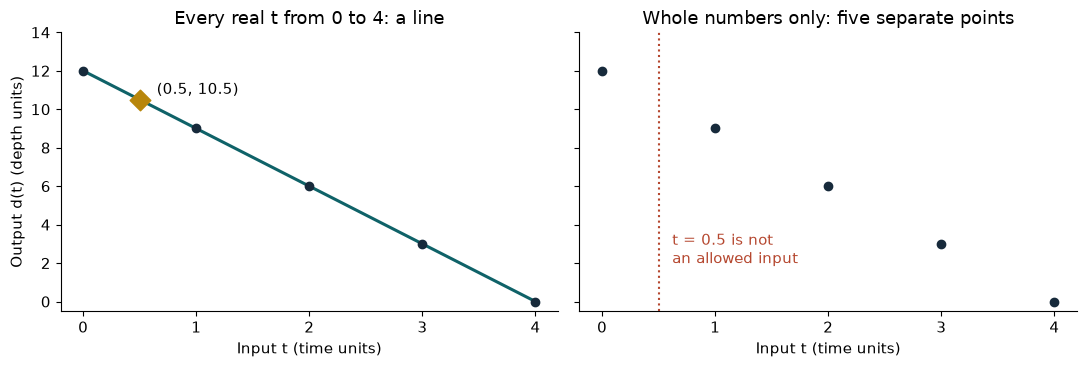

In [3]:
whole = np.arange(0, 5)
tt = np.linspace(0, 4, 81)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)

a1.plot(tt, d(tt), color=TEAL, linewidth=2.2)
a1.scatter(whole, d(whole), color=NAVY, zorder=3)
a1.scatter([0.5], [d(0.5)], marker="D", s=110, color=GOLD, zorder=4)
a1.text(0.65, d(0.5) + 0.3, "(0.5, 10.5)", fontsize=11)
a1.set_title("Every real t from 0 to 4: a line")

a2.scatter(whole, d(whole), color=NAVY, zorder=3)
a2.axvline(0.5, color=RED, linestyle="dotted")
a2.text(0.62, 2, "t = 0.5 is not\nan allowed input", color=RED)
a2.set_title("Whole numbers only: five separate points")

for ax in (a1, a2):
    ax.set_xlabel("Input t (time units)")
    ax.set_xticks(range(5))
    ax.set_ylim(-0.5, 14)
a1.set_ylabel("Output d(t) (depth units)")
finish(fig)

**What this shows.** When every real $t$ from 0 to 4 is allowed, the rule gives an output at each one, so the points join into a line. When only whole numbers are allowed, the graph is five separate dots, and drawing a line between them would suggest values the model excludes.

**Where it stops working.** The chapter declares every real $t$ from 0 through 4. The whole-number case is the same rule with a count domain, like counting tickets. Before you connect dots on any graph, ask whether the inputs between them are allowed.

## 2. Slope from two points

**The question:** From $(-2, 5)$ to $(2, -3)$, how fast does the output change, and does the order of subtraction matter?

**The equations from the chapter:**

$$\frac{-8}{4} = -2 \qquad\qquad \frac{5 - (-3)}{-2 - 2} = \frac{8}{-4} = -2$$

**What the symbols mean:** Slope is the vertical change divided by the horizontal change. Both changes must go from the same start point to the same end point.

Predict first: if you reverse only the bottom (the horizontal order), will the slope still be $-2$, or flip sign?

In [4]:
P, Q = (-2, 5), (2, -3)

def show(label, num_a, num_b, den_a, den_b):
    rise, run = num_a - num_b, den_a - den_b
    print(f"{label}")
    print(f"  vertical change:   {num_a} - {par(num_b)} = {rise}")
    print(f"  horizontal change: {den_a} - {par(den_b)} = {run}")
    print(f"  slope = {rise} / {par(run)} = {q(Fraction(rise, run))}")
    print()

show("First to second (both changes):", Q[1], P[1], Q[0], P[0])
show("Second to first (both changes):", P[1], Q[1], P[0], Q[0])
show("Mixed: numerator forward, denominator reversed (the error):", Q[1], P[1], P[0], Q[0])

print("A vertical pair, (-2, 5) and (-2, 1):")
print(f"  vertical change:   1 - 5 = {1 - 5}")
print(f"  horizontal change: -2 - (-2) = {-2 - (-2)}")
print("  slope = -4 / 0, and division by zero is undefined. A vertical line has no slope.")
print()
print("Check from (0, 1) to (2, -3): (-3 - 1) / (2 - 0) =", q(Fraction(-3 - 1, 2 - 0)))

First to second (both changes):
  vertical change:   -3 - 5 = -8
  horizontal change: 2 - (-2) = 4
  slope = -8 / 4 = -2

Second to first (both changes):
  vertical change:   5 - (-3) = 8
  horizontal change: -2 - 2 = -4
  slope = 8 / (-4) = -2

Mixed: numerator forward, denominator reversed (the error):
  vertical change:   -3 - 5 = -8
  horizontal change: -2 - 2 = -4
  slope = -8 / (-4) = 2

A vertical pair, (-2, 5) and (-2, 1):
  vertical change:   1 - 5 = -4
  horizontal change: -2 - (-2) = 0
  slope = -4 / 0, and division by zero is undefined. A vertical line has no slope.

Check from (0, 1) to (2, -3): (-3 - 1) / (2 - 0) = -2


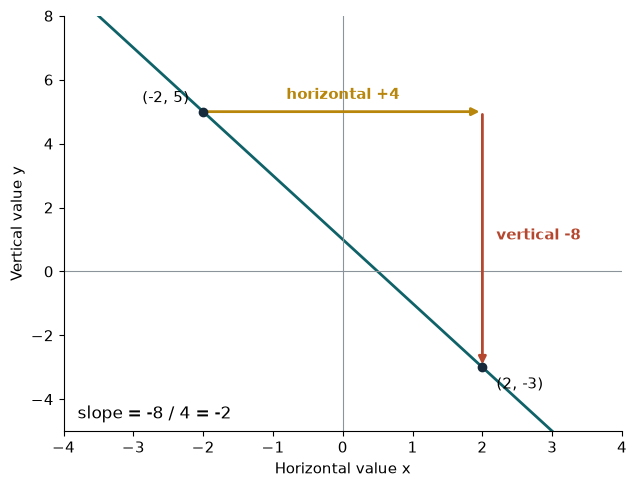

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5))
xx = np.linspace(-3.5, 3.5, 30)
ax.plot(xx, -2 * xx + 1, color=TEAL, linewidth=2)
ax.axhline(0, color=GREY, linewidth=0.8); ax.axvline(0, color=GREY, linewidth=0.8)
ax.annotate("", xy=(2, 5), xytext=(-2, 5), arrowprops=dict(arrowstyle="-|>", color=GOLD, linewidth=2))
ax.annotate("", xy=(2, -3), xytext=(2, 5), arrowprops=dict(arrowstyle="-|>", color=RED, linewidth=2))
ax.text(0, 5.4, "horizontal +4", color=GOLD, ha="center", fontweight="bold")
ax.text(2.2, 1, "vertical -8", color=RED, fontweight="bold")
ax.scatter([-2, 2], [5, -3], color=NAVY, zorder=4)
ax.text(-2.2, 5.3, "(-2, 5)", ha="right")
ax.text(2.2, -3.3, "(2, -3)", va="top")
ax.text(-3.8, -4.6, "slope = -8 / 4 = -2", fontsize=12)
ax.set_xlim(-4, 4); ax.set_ylim(-5, 8)
ax.set_xlabel("Horizontal value x"); ax.set_ylabel("Vertical value y")
finish(fig)

**What this shows.** The arrows are the two changes. Reversing both flips both signs, so the fraction is unchanged: $8/(-4)$ and $-8/4$ are both $-2$. Reversing just one flips only one sign and gives $+2$, which cannot be right for a line that clearly falls.

**Where it stops working.** The axes are assumed to increase to the right and upward. If both points share the same horizontal value, the line is vertical and its slope is undefined (not zero).

## 3. Intercepts and the domain

**The question:** The line $y = 2x + 3$ crosses the $x$-axis at $(-3/2, 0)$. Does that point mean anything in the plan?

**The equations from the chapter:**

$$0 = 2x + 3 \qquad\qquad x = -\frac{3}{2}$$

**What the symbols mean:** An *intercept* is where a graph meets an axis. Set $x = 0$ to find the $y$-intercept and $y = 0$ to find the $x$-intercept. In the example plans, the allowed inputs are $0 \le x \le 6$.

Predict first: for rule B, $y = x + 7$, is its $x$-intercept inside the plan?

In [6]:
rules = {"A": (2, 3), "B": (1, 7)}
for name, (m, c) in rules.items():
    xint = Fraction(-c, m)
    print(f"Rule {name}: y = {'2x' if m == 2 else 'x'} + {c}")
    print(f"  y-intercept: x = 0 gives y = {"2(0)" if m == 2 else "0"} + {c} = {c}, the point (0, {c})")
    if m == 2:
        print(f"  x-intercept: 0 = 2x + {c}, so -{c} = 2x, so x = {q(xint)}, the point ({q(xint)}, 0)")
    else:
        print(f"  x-intercept: 0 = x + {c}, so x = -{c}, the point ({q(xint)}, 0)")
    inside = 0 <= xint <= 6
    print(f"  is x = {q(xint)} inside 0 <= x <= 6? {inside}")
    print()
print("Check: for y = x + 7 the y-intercept is (0, 7), and its input 0 is inside the plan domain.")

Rule A: y = 2x + 3
  y-intercept: x = 0 gives y = 2(0) + 3 = 3, the point (0, 3)
  x-intercept: 0 = 2x + 3, so -3 = 2x, so x = -3/2, the point (-3/2, 0)
  is x = -3/2 inside 0 <= x <= 6? False

Rule B: y = x + 7
  y-intercept: x = 0 gives y = 0 + 7 = 7, the point (0, 7)
  x-intercept: 0 = x + 7, so x = -7, the point (-7, 0)
  is x = -7 inside 0 <= x <= 6? False

Check: for y = x + 7 the y-intercept is (0, 7), and its input 0 is inside the plan domain.


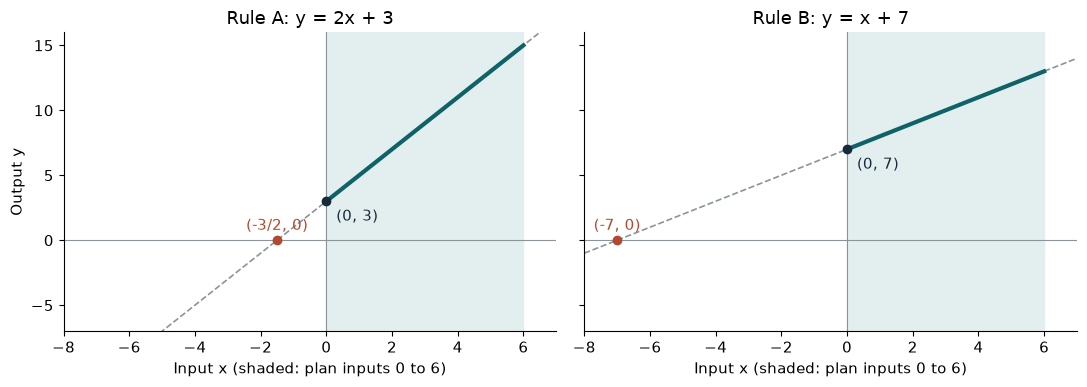

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
xx = np.linspace(-8, 7, 60)
for ax, (name, (m, c)) in zip(axes, rules.items()):
    xint = Fraction(-c, m)
    ax.axhline(0, color=GREY, linewidth=0.8); ax.axvline(0, color=GREY, linewidth=0.8)
    ax.axvspan(0, 6, color="#e3efee", zorder=0)
    ax.plot(xx, m * xx + c, color=GREY, linestyle="dashed", linewidth=1.2)
    inside = np.linspace(0, 6, 30)
    ax.plot(inside, m * inside + c, color=TEAL, linewidth=3)
    ax.scatter([0], [c], color=NAVY, zorder=4)
    ax.text(0.3, c - 0.6, f"(0, {c})", color=NAVY, va="top")
    ax.scatter([float(xint)], [0], color=RED, zorder=4)
    ax.text(float(xint), 0.8, f"({q(xint)}, 0)", color=RED, ha="center")
    ax.set_title(f"Rule {name}: y = {'2x' if m == 2 else 'x'} + {c}")
    ax.set_xlim(-8, 7); ax.set_ylim(-7, 16)
    ax.set_xlabel("Input x (shaded: plan inputs 0 to 6)")
axes[0].set_ylabel("Output y")
finish(fig)

**What this shows.** Both intercepts belong to the full line. The shaded band is the plan's domain, and only the solid part of each line describes the plan. For rule A, the $x$-intercept $(-3/2, 0)$ sits outside the band, so it is a fact about the line but has no meaning inside the plan. Rule B's $y$-intercept $(0, 7)$ is inside.

**Where it stops working.** The plans are invented. The algebra holds for every real $x$; the plan domain is a choice about which inputs the story covers. Check that a calculated intercept lies among the allowed inputs before you give it a meaning.

## 4. Where the lines cross

**The question:** What does it mean that $A$ and $B$ cross at $(4, 11)$?

**The equations from the chapter:**

$$A(x) = B(x) \qquad\qquad 2x + 3 = x + 7$$

**What the symbols mean:** $A(x) = 2x + 3$ and $B(x) = x + 7$ are the two example rules, for inputs from 0 through 6. Where their outputs are equal, the lines meet.

Predict first: at $x = 6$, which rule gives the larger output, and by how much?

In [8]:
A = lambda x: 2 * x + 3
B = lambda x: x + 7

x = 4
print(f"At x = {x}:")
print(f"  A({x}) = 2({x}) + 3 = {2 * x} + 3 = {A(x)}")
print(f"  B({x}) = {x} + 7 = {B(x)}")
print(f"  equal outputs, so ({x}, {A(x)}) is the intersection.")
print()
print("Solve 2x + 3 = x + 7:")
print("  subtract x from both sides: x + 3 = 7")
print("  subtract 3 from both sides: x = 4")
print()
print("All four inputs:")
for x in (0, 2, 4, 6):
    a, b = A(x), B(x)
    who = "tie" if a == b else ("A" if a > b else "B") + f" larger by {abs(a - b)}"
    print(f"  x = {x}: A = 2({x}) + 3 = {a};  B = {x} + 7 = {b};  {who}")

At x = 4:
  A(4) = 2(4) + 3 = 8 + 3 = 11
  B(4) = 4 + 7 = 11
  equal outputs, so (4, 11) is the intersection.

Solve 2x + 3 = x + 7:
  subtract x from both sides: x + 3 = 7
  subtract 3 from both sides: x = 4

All four inputs:
  x = 0: A = 2(0) + 3 = 3;  B = 0 + 7 = 7;  B larger by 4
  x = 2: A = 2(2) + 3 = 7;  B = 2 + 7 = 9;  B larger by 2
  x = 4: A = 2(4) + 3 = 11;  B = 4 + 7 = 11;  tie
  x = 6: A = 2(6) + 3 = 15;  B = 6 + 7 = 13;  A larger by 2


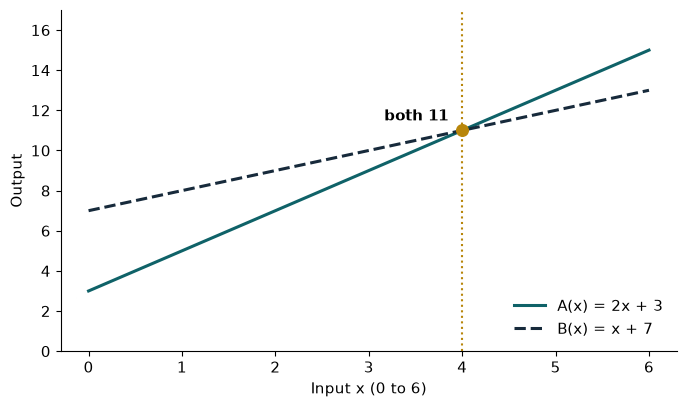

In [9]:
xx = np.linspace(0, 6, 61)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(xx, 2 * xx + 3, color=TEAL, linewidth=2.2, label="A(x) = 2x + 3")
ax.plot(xx, xx + 7, color=NAVY, linewidth=2.2, linestyle="dashed", label="B(x) = x + 7")
ax.axvline(4, color=GOLD, linestyle="dotted")
ax.scatter([4], [11], s=70, color=GOLD, zorder=4)
ax.text(3.85, 11.5, "both 11", ha="right", fontweight="bold")
ax.set_xlabel("Input x (0 to 6)"); ax.set_ylabel("Output")
ax.set_xticks(range(7)); ax.set_ylim(0, 17)
ax.legend(frameon=False, loc="lower right")
finish(fig)

**What this shows.** At each input the two lines give two outputs. They are equal only at $x = 4$, where both give 11. Left of 4, $B$ is higher; right of 4, $A$ is higher.

**Where it stops working.** The rules are invented, so the picture says nothing about which output is better until the story says what the output means. And reading a crossing off a graph is only an estimate; putting the input into both rules (or solving $2x + 3 = x + 7$) is what confirms it.

## Practice

**1.** In the whole-interval domain, what output goes with $t = 3.5$ in $d(t) = 12 - 3t$?

<details><summary>Show answer</summary>

$d(3.5) = 12 - 3(3.5) = 12 - 10.5 = 1.5$, so the point $(3.5, 1.5)$ is on the graph.

</details>

**2.** What is the slope from $(0, 1)$ to $(2, -3)$?

<details><summary>Show answer</summary>

Vertical change: $-3 - 1 = -4$. Horizontal change: $2 - 0 = 2$. Slope $= -4/2 = -2$, the same as before, because both points sit on the same line.

</details>

**3.** At $x = 2$, what are $A(2)$ and $B(2)$, and which is larger?

<details><summary>Show answer</summary>

$A(2) = 2(2) + 3 = 7$ and $B(2) = 2 + 7 = 9$, so $B$ is larger by 2.

</details>